# Tomato Leaf Disease Classification – ML Cycle
Image classification with MobileNetV2 transfer learning. Run from the repo root (`%cd ..` below).

In [1]:
from pathlib import Path
import os, json, random
repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "data_acquisition.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the project containing src/data_acquisition.py")
os.chdir(repo_root)
os.environ["TFDS_DATA_DIR"] = str((repo_root / "data" / "tfds").resolve())
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from src.preprocessing import *
from src.model import *
from src.prediction import predict

## 1. Data acquisition
Downloads a subset of PlantVillage (4 tomato classes). Skip if `data/train` is already filled.

In [2]:
from src.data_acquisition import acquire
if not count_images('data/train'):
    acquire(per_class=400)
print(count_images('data/train')); print(count_images('data/test'))

{'Tomato___Early_blight': 326, 'Tomato___Late_blight': 331, 'Tomato___Leaf_Mold': 327, 'Tomato___healthy': 333}
{'Tomato___Early_blight': 74, 'Tomato___Late_blight': 69, 'Tomato___Leaf_Mold': 73, 'Tomato___healthy': 67}


## 2. Data processing & visualisation

Found 1317 files belonging to 4 classes.


Using 1054 files for training.


Found 1317 files belonging to 4 classes.


Using 263 files for validation.


Found 283 files belonging to 4 classes.


['Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___healthy']


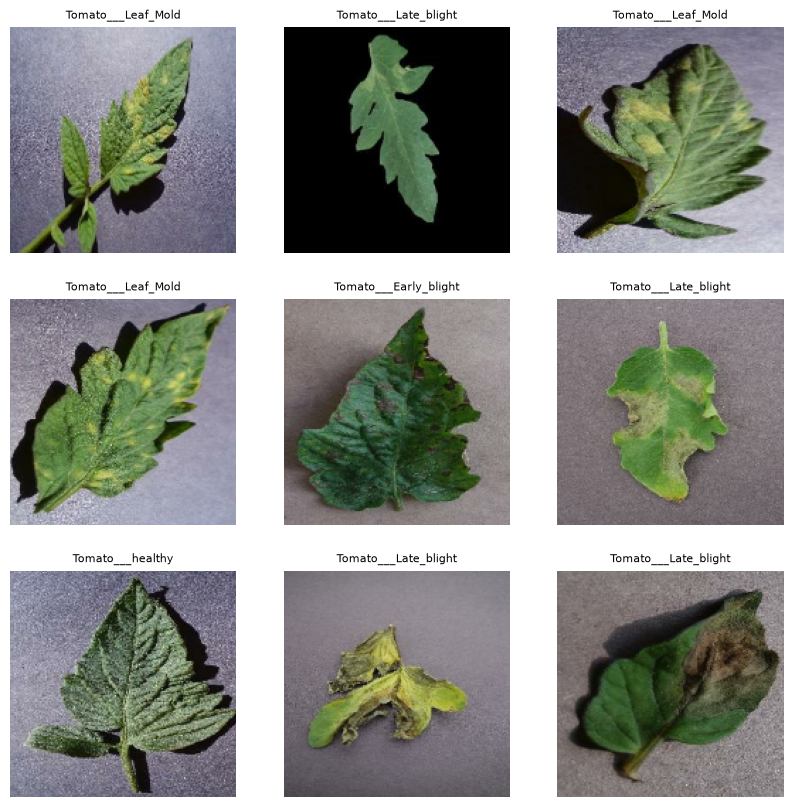

In [3]:
train_ds, val_ds, test_ds, names = get_datasets()
print(names)
plt.figure(figsize=(10,10))
for x,y in train_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1); plt.imshow(x[i].numpy().astype('uint8')); plt.title(names[y[i]],fontsize=8); plt.axis('off')

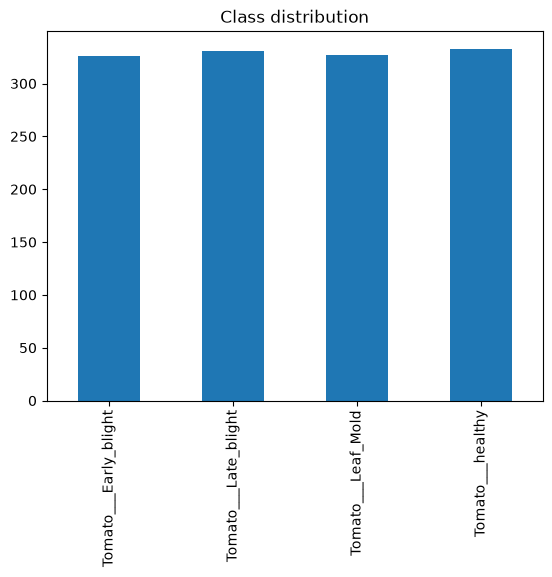

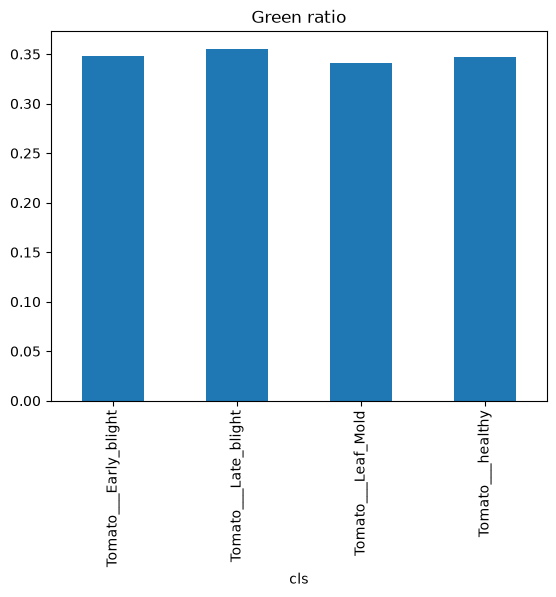

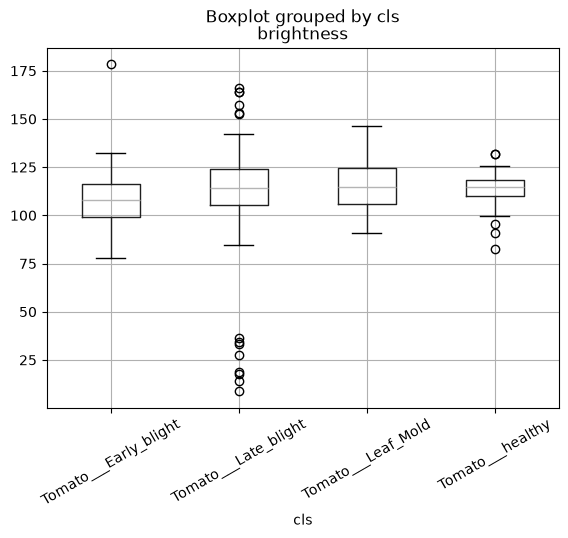

In [4]:
# Feature 1: class distribution; Feature 2: green ratio; Feature 3: brightness
import pandas as pd
from PIL import Image
rows=[]
for c in names:
    fs=os.listdir(f'data/train/{c}')[:80]
    for f in fs:
        a=np.array(Image.open(f'data/train/{c}/{f}').convert('RGB').resize((128,128)),dtype=float)
        r,g,b=a[...,0].mean(),a[...,1].mean(),a[...,2].mean()
        rows.append(dict(cls=c,green_ratio=g/(r+g+b),brightness=a.mean()))
df=pd.DataFrame(rows)
pd.Series(count_images('data/train')).plot.bar(title='Class distribution'); plt.show()
df.groupby('cls').green_ratio.mean().plot.bar(title='Green ratio'); plt.show()
df.boxplot(column='brightness',by='cls',rot=30); plt.show()

**Interpretation:** (1) Training counts are nearly balanced: healthy has the most images (333) and early blight the fewest (326), a difference of just 7, so no class dominates accuracy. (2) Healthy leaves have a mean green ratio of 0.3475, almost the same as diseased leaves combined (about 0.3485); late blight is highest (0.3554) and leaf mold lowest (0.3414). Green ratio alone separates the classes weakly. (3) Brightness overlaps substantially: all four classes' middle 50% ranges intersect from about 110 to 116 on the 0-255 scale, so brightness alone is a weak class separator.

## 3. Model creation & training

In [5]:
model = build_model(len(names)); model.summary()

   8192/9406464 [..............................] - ETA: 0s

  16384/9406464 [..............................] - ETA: 1:53

  32768/9406464 [..............................] - ETA: 1:24

  40960/9406464 [..............................] - ETA: 1:28

  57344/9406464 [..............................] - ETA: 1:16

  65536/9406464 [..............................] - ETA: 1:15

... (52 outputs left out)

Total params: 2263108 (8.63 MB)


Trainable params: 5124 (20.02 KB)


Non-trainable params: 2257984 (8.61 MB)


_________________________________________________________________


In [6]:
model, metrics, hist = train(epochs=8, fine_tune_epochs=3)

Found 1317 files belonging to 4 classes.


Using 1054 files for training.


Found 1317 files belonging to 4 classes.


Using 263 files for validation.


Found 283 files belonging to 4 classes.


Epoch 1/8


... (381 outputs left out)

32/33 [============================>.] - ETA: 0s - loss: 0.3381 - accuracy: 0.8848

33/33 [==============================] - ETA: 0s - loss: 0.3367 - accuracy: 0.8843

33/33 [==============================] - 32s 959ms/step - loss: 0.3367 - accuracy: 0.8843 - val_loss: 0.3464 - val_accuracy: 0.8707


C:\Users\upremier\Downloads\Leaf_Disease_ML\.venv\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


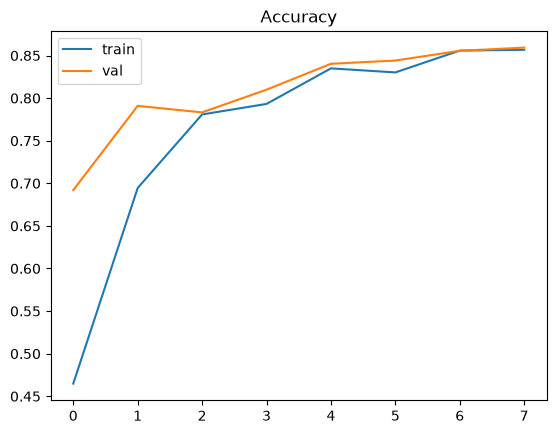

In [7]:
plt.plot(hist.history['accuracy'],label='train'); plt.plot(hist.history['val_accuracy'],label='val'); plt.legend(); plt.title('Accuracy'); plt.show()

## 4. Model testing (Accuracy, Precision, Recall, F1, Loss, Confusion matrix)

{'accuracy': 0.8516, 'precision': 0.8588, 'recall': 0.8516, 'f1': 0.8479, 'loss': 0.4067}

Tomato___Early_blight {'precision': 0.891, 'recall': 0.662, 'f1-score': 0.76, 'support': 74.0}
Tomato___Late_blight {'precision': 0.892, 'recall': 0.841, 'f1-score': 0.866, 'support': 69.0}
Tomato___Leaf_Mold {'precision': 0.764, 'recall': 0.932, 'f1-score': 0.84, 'support': 73.0}
Tomato___healthy {'precision': 0.892, 'recall': 0.985, 'f1-score': 0.936, 'support': 67.0}
macro avg {'precision': 0.86, 'recall': 0.855, 'f1-score': 0.85, 'support': 283.0}
weighted avg {'precision': 0.859, 'recall': 0.852, 'f1-score': 0.848, 'support': 283.0}


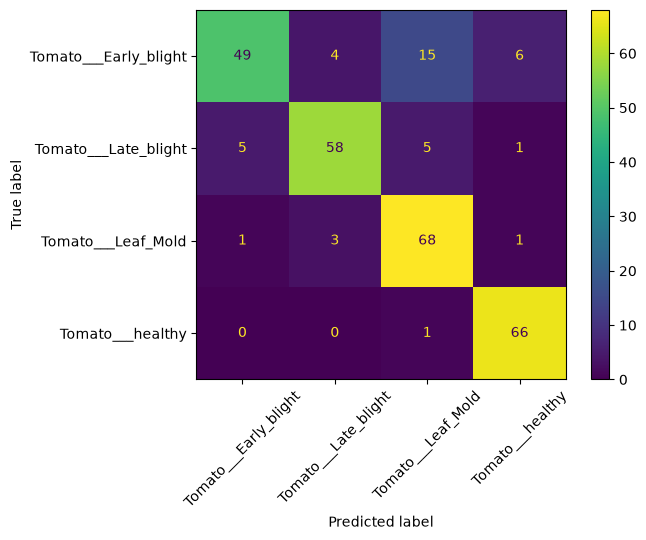

In [8]:
print({k:round(metrics[k],4) for k in ['accuracy','precision','recall','f1','loss']})
print(classification_report(*zip(*[(y,p) for y,p in []]) ) if False else '')
for c,v in metrics['report'].items():
    if isinstance(v,dict): print(c, {k:round(x,3) for k,x in v.items()})
ConfusionMatrixDisplay(np.array(metrics['confusion_matrix']),display_labels=names).plot(xticks_rotation=45)

## 5. Prediction function

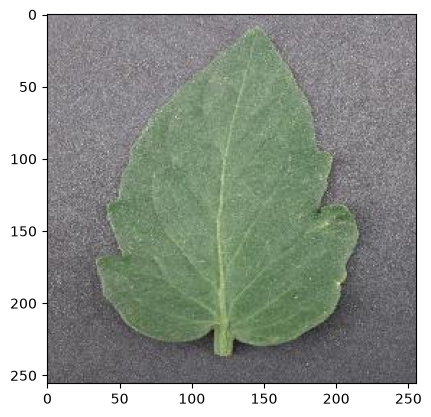

{'label': 'Tomato___healthy', 'confidence': 0.9993164539337158, 'probabilities': {'Tomato___Early_blight': 5.083643918624148e-05, 'Tomato___Late_blight': 0.0005134607199579477, 'Tomato___Leaf_Mold': 0.00011932691268157214, 'Tomato___healthy': 0.9993164539337158}}


In [9]:
f=random.choice([os.path.join(r,x) for r,_,fs in os.walk('data/test') for x in fs if x.endswith('.jpg')])
plt.imshow(plt.imread(f)); plt.show()
print(predict(open(f,'rb').read()))

## 6. Retraining
```python
from src.model import retrain
retrain()   # merges data/uploads into data/train, retrains and overwrites models/leaf_model.h5
```